In [82]:
import torchvision.datasets as datasets
import torchvision.transforms as transforms
import torch
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [4]:
transform = transforms.Compose([
    transforms.ToTensor(),
])

# Download and load the EuroSAT dataset (RGB version)
dataset = datasets.EuroSAT(
    root="../data/raw/EuroSAT",
    transform=transform,
    download=True,
)

In [7]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


In [8]:
generator = torch.Generator().manual_seed(0)
train_set, val_set, test_set = torch.utils.data.random_split(
    dataset, [.8, .1, .1], generator = generator)


In [9]:
# create data loader for training data
stats_dataloader = DataLoader(train_set, batch_size = 512, shuffle = False)

We want to transform the data by normalising it. To this end, we first compute its mean and standard deviation

In [10]:
s = torch.zeros(3, dtype=torch.float64)
s2 = torch.zeros(3, dtype=torch.float64)
N = 0
for batch, label in stats_dataloader:
    batch = batch.double()
    s += batch.sum(dim = (0, 2, 3))    # batch has shape [512, 3, 64, 64] : [images, channels, height, width]
    s2 += (batch ** 2).sum(dim = (0, 2, 3))
    N += batch.shape[0] * batch.shape[2] * batch.shape[3]

mean = s / N
stdv = (s2 / N - mean ** 2) ** .5

print("mean:", mean)
print("stdv:", stdv)

mean: tensor([0.3433, 0.3797, 0.4075], dtype=torch.float64)
stdv: tensor([0.2017, 0.1364, 0.1152], dtype=torch.float64)


Define the normalisation transform for the dataset. This will not change the images themselves, but rather transform them whenever they are requested from the dataset.

In [11]:
dataset.transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean.tolist(), stdv.tolist())
])

In [53]:
loader_gen = torch.Generator().manual_seed(0)
train_dataloader = DataLoader(train_set, batch_size = 64, shuffle = True, generator = loader_gen)
val_dataloader = DataLoader(val_set, batch_size = 64, shuffle = False, generator = loader_gen)
test_dataloader = DataLoader(test_set, batch_size = 64, shuffle = False, generator = loader_gen)

Plot some images from the training set

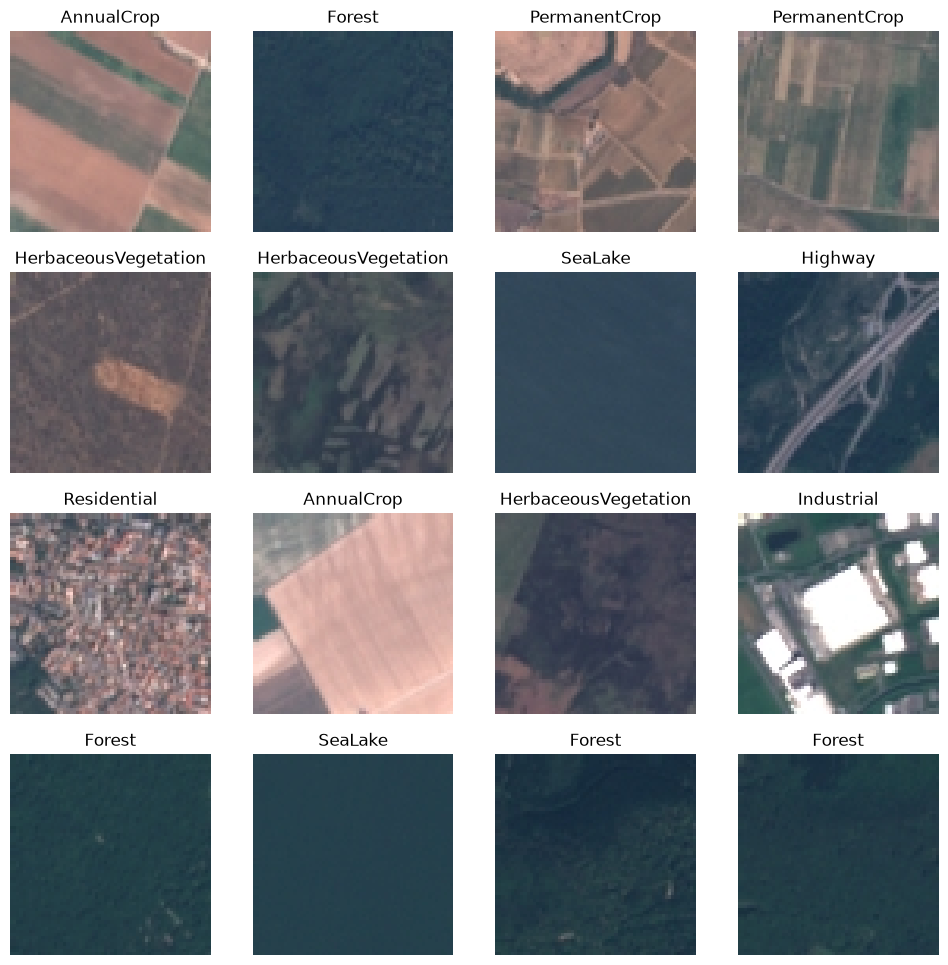

In [13]:
mean_t = mean.float().view(3, 1, 1)
std_t  = stdv.float().view(3, 1, 1)


figure = plt.figure(figsize=(12, 12))
cols, rows = 4, 4
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(train_set), size=(1,)).item()
    img, label = train_set[sample_idx]
    img = (img * std_t + mean_t).clamp(0, 1)

    # torch and matplotlib have different channel orders, so permute the image tensor
    img = img.permute(1, 2, 0)
    figure.add_subplot(rows, cols, i)
    plt.title(dataset.classes[label])
    plt.axis("off")
    plt.imshow(img)  

plt.show()

### Define the CNN model

EuroSAT land-cover classes are defined by local spatial patterns. We will thus use a CNN, which keeps the pixel neighbourhood and learns these patterns with shared filters while far fewer parameters than a fully connected network.

In [14]:
from torch import nn

def conv_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size = 3, padding = 1, bias = False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2)
    )


class CNN(nn.Module):
    def __init__(self, n_classes = 10):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(3, 32),
            conv_block(32, 64),
            conv_block(64, 128)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128 * 8 * 8, n_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


In [17]:
model = CNN().to(device)
tensor = torch.zeros(2, 3, 64, 64).to(device)
model(tensor).shape

torch.Size([2, 10])

In [35]:
def train_one_epoch(model, dataloader, loss_fn, optimizer, device):
    model.train()
    total_loss = 0.0
    Ncorrect = 0
    Ntotal = 0

    for X, y in dataloader:
        # move data to device
        X, y = X.to(device), y.to(device)

        # forward pass
        logits = model(X)

        # compute loss
        loss = loss_fn(logits, y)

        # backward pass
        optimizer.zero_grad()
        loss.backward()

        # update weights
        optimizer.step()

        # compute figures of merit
        total_loss += loss.item() * X.shape[0]
        Ncorrect += (logits.argmax(dim=1) == y).sum().item()
        Ntotal += X.shape[0]

    return total_loss / Ntotal, Ncorrect / Ntotal

def evaluate(model, dataloader, loss_fn, device):
    model.eval()
    total_loss = 0.0
    Ncorrect = 0
    Ntotal = 0

    with torch.no_grad():
        for X, y in dataloader:
            # move data to device
            X, y = X.to(device), y.to(device)
        
            # forward pass
            logits = model(X)
        
            # compute loss
            loss = loss_fn(logits, y)

            # compute figures of merit
            total_loss += loss.item() * X.shape[0]
            Ncorrect += (logits.argmax(dim=1) == y).sum().item()
            Ntotal += X.shape[0]

    return total_loss / Ntotal, Ncorrect / Ntotal



Test the model with a single batch

In [20]:
model = CNN().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr = 1e-3)

X, y = next(iter(train_dataloader))
X = X.to(device)
y = y.to(device)

model.train()
Nsteps = 100
for step in range(Nsteps):
    loss = loss_fn(model(X), y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if step % 10 == 0:
        print(step, loss.item())


0 2.553154706954956
10 0.2612326145172119
20 0.030163880437612534
30 0.004910165909677744
40 0.0022831130772829056
50 0.0014449404552578926
60 0.0008879591478034854
70 0.0007459677290171385
80 0.0007064159726724029
90 0.0005821833619847894


### Train the model

Let us first try with a constant learning rate

In [69]:
lr = 1e-3
Nepochs = 15
torch.manual_seed(0)

model = CNN().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr = lr)

metrics = []
best_acc = 0.0
for epoch in range(Nepochs):
    train_loss, train_acc = train_one_epoch(model, train_dataloader, loss_fn, optimizer, device) 
    val_loss, val_acc = evaluate(model, val_dataloader, loss_fn, device)

    metrics.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "train_acc": train_acc,
            "val_loss": val_loss,
            "val_acc": val_acc,
        })
    
    if val_acc > best_acc:
        best_acc = val_acc
        torch.save(model.state_dict(), "../data/processed/eurosat_cnn_best.pt")

    print(f"{epoch:2d}:   train {train_loss:.3f}/{train_acc:.3f},   validation {val_loss:.3f} / {val_acc:.3f}")

metrics_df = pd.DataFrame(metrics).set_index("epoch")

 0:   train 0.973/0.678,   validation 0.571 / 0.801
 1:   train 0.616/0.796,   validation 0.636 / 0.800
 2:   train 0.493/0.837,   validation 0.463 / 0.857
 3:   train 0.415/0.861,   validation 0.389 / 0.867
 4:   train 0.347/0.884,   validation 0.371 / 0.885
 5:   train 0.312/0.893,   validation 0.468 / 0.847
 6:   train 0.274/0.907,   validation 0.515 / 0.844
 7:   train 0.261/0.911,   validation 0.374 / 0.889
 8:   train 0.221/0.926,   validation 0.368 / 0.878
 9:   train 0.196/0.934,   validation 0.310 / 0.901
10:   train 0.187/0.935,   validation 0.319 / 0.902
11:   train 0.161/0.943,   validation 0.327 / 0.904
12:   train 0.154/0.947,   validation 0.276 / 0.916
13:   train 0.128/0.957,   validation 0.345 / 0.901
14:   train 0.130/0.954,   validation 0.276 / 0.919


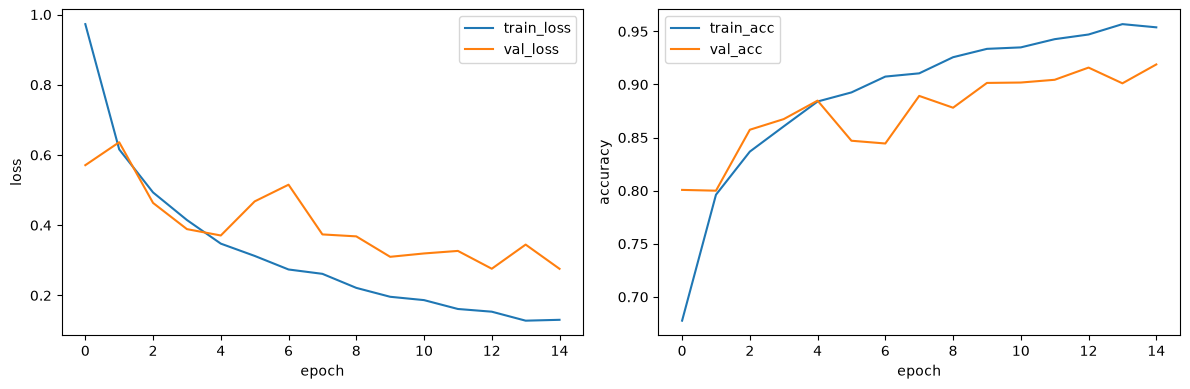

In [70]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
metrics_df[["train_loss", "val_loss"]].plot(ax=axes[0], ylabel="loss")
metrics_df[["train_acc", "val_acc"]].plot(ax=axes[1], ylabel="accuracy")
plt.tight_layout()
plt.show()

Validation bounces heavily, indicating that the constant learning rate is too large at the final epochs and the weights keep overshooting near the optimum. Picking the best epoch from such a noisy curve gives a rather optimistic estimate: let's try with a learning-rate schedule instead

In [71]:
lr = 1e-3
Nepochs = 15
torch.manual_seed(0)

model = CNN().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr = lr)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max = Nepochs)

metrics = []
best_acc = 0.0
for epoch in range(Nepochs):
    train_loss, train_acc = train_one_epoch(model, train_dataloader, loss_fn, optimizer, device) 
    val_loss, val_acc = evaluate(model, val_dataloader, loss_fn, device)
    current_lr = scheduler.get_last_lr()[0]
    scheduler.step()

    metrics.append({
        "epoch": epoch,
        "lr": current_lr,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc,
    })
    
    if val_acc > best_acc:
        best_acc = val_acc
        torch.save(model.state_dict(), "../data/processed/eurosat_cnn_best.pt")

    print(f"{epoch:2d}:   lr {current_lr:.1e},   train {train_loss:.3f}/{train_acc:.3f},   validation {val_loss:.3f} / {val_acc:.3f}")

metrics_df = pd.DataFrame(metrics).set_index("epoch")

 0:   lr 1.0e-03,   train 1.004/0.668,   validation 0.655 / 0.793
 1:   lr 9.9e-04,   train 0.649/0.790,   validation 0.782 / 0.772
 2:   lr 9.6e-04,   train 0.482/0.840,   validation 0.514 / 0.833
 3:   lr 9.0e-04,   train 0.413/0.862,   validation 0.436 / 0.862
 4:   lr 8.3e-04,   train 0.339/0.887,   validation 0.413 / 0.865
 5:   lr 7.5e-04,   train 0.275/0.906,   validation 0.361 / 0.884
 6:   lr 6.5e-04,   train 0.255/0.915,   validation 0.447 / 0.864
 7:   lr 5.5e-04,   train 0.193/0.932,   validation 0.338 / 0.899
 8:   lr 4.5e-04,   train 0.163/0.943,   validation 0.263 / 0.918
 9:   lr 3.5e-04,   train 0.137/0.954,   validation 0.305 / 0.908
10:   lr 2.5e-04,   train 0.120/0.959,   validation 0.233 / 0.927
11:   lr 1.7e-04,   train 0.098/0.967,   validation 0.225 / 0.926
12:   lr 9.5e-05,   train 0.087/0.972,   validation 0.203 / 0.930
13:   lr 4.3e-05,   train 0.075/0.977,   validation 0.213 / 0.931
14:   lr 1.1e-05,   train 0.074/0.976,   validation 0.198 / 0.932


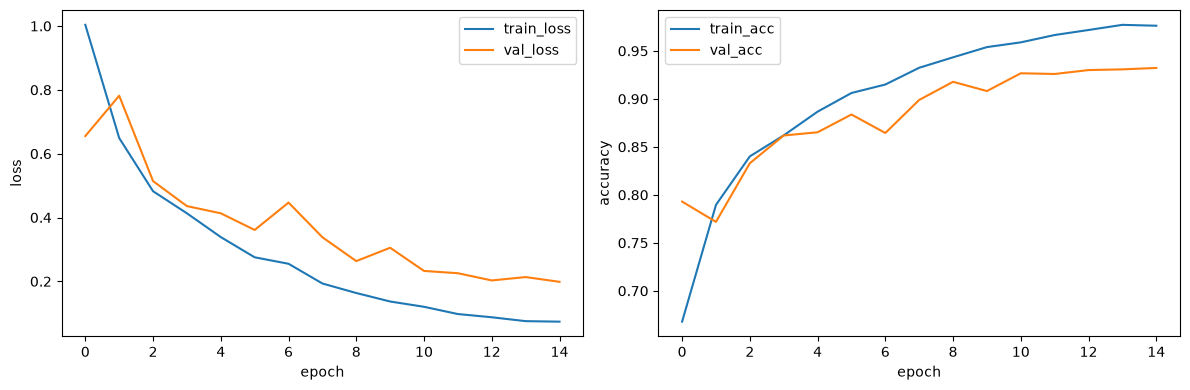

In [72]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
metrics_df[["train_loss", "val_loss"]].plot(ax=axes[0], ylabel="loss")
metrics_df[["train_acc", "val_acc"]].plot(ax=axes[1], ylabel="accuracy")
plt.tight_layout()
plt.show()


The validation curve settles as the learning rate drops, and the best epoch is the final one

### Test the model

In [98]:
# load the optimal model
path = "../data/processed/eurosat_cnn_best.pt"
model = CNN().to(device)
model.load_state_dict(torch.load(path, weights_only = True))

# evaluate it on the test set
test_loss, test_acc = evaluate(model, test_dataloader, loss_fn, device)

# compute the 95% confidence interval for the accuracy
std_error = np.sqrt(test_acc * (1 - test_acc) / len(test_dataloader.dataset))
ci = 1.96 * std_error

print("test loss:", np.round(test_loss, 3))
print("test accuracy:", np.round(test_acc, 3))
print("95% CI for test accuracy: [", np.round(test_acc - ci, 3), ",", np.round(test_acc + ci, 3), "]")


test loss: 0.163
test accuracy: 0.949
95% CI for test accuracy: [ 0.94 , 0.957 ]


The trained model obtains around a 95% accuracy on the test data. Let us break it down and look how it performs for each class, and compute the confusion matrix.

per class recall (correct / true count):
Highway                 0.898
HerbaceousVegetation    0.912
River                   0.917
PermanentCrop           0.921
AnnualCrop              0.940
Pasture                 0.966
Forest                  0.974
Industrial              0.975
Residential             0.989
SeaLake                 0.990
dtype: float64


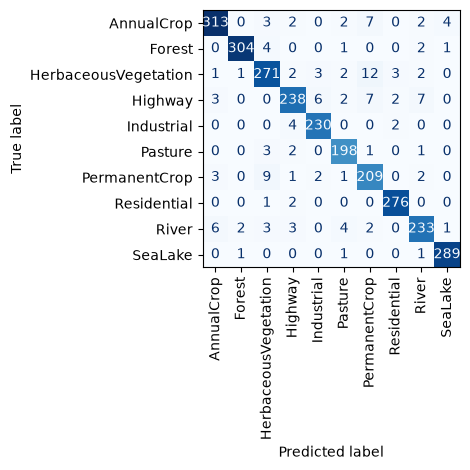

In [ ]:
# collect predictions from the test set
model.eval()
y_true = []
y_pred = []
with torch.no_grad():
    for X, y in test_dataloader:
        logits = model (X.to(device))
        y_pred.append(logits.argmax(dim = 1).cpu())
        y_true.append(y)
y_true = torch.cat(y_true).numpy()
y_pred = torch.cat(y_pred).numpy()

# compute confusion matrix and per-class recall
cm = confusion_matrix(y_true, y_pred)
per_class_acc = cm.diagonal() / cm.sum(axis = 1)



print("per class recall (correct / true count):")
print(pd.Series(per_class_acc, index=dataset.classes).sort_values().round(3))

disp = ConfusionMatrixDisplay(confusion_matrix = cm, display_labels = dataset.classes)
disp.plot(colorbar = False, xticks_rotation = 90, cmap = "Blues")
plt.tight_layout()

From the per-class recall we see that the model learns the more homogeneous areas the better: large bodies of water or residential areas are almost perfectly identified. On the other hand, classes characterised by distinct thin features, such as a river's edge or a highway, are harder to learn.